# Group Assignment (Demo 4)
This notebook contains introductory content for the Group Assignment, licgcd to Big Data session 5: Visualizations.

In what follows, we will:
1. Create insightful technical analysis plots 
2. Analyze news article topics 
3. Visually evaluate and explain models

# Initialize Spark Environment

## Initialize PySpark & import packages

In [1]:
# import findspark
import findspark
# initialize findspark with spark directory
findspark.init()
# import pyspark
import pyspark
# create spark contextp
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

In [2]:
# inspect spark session
spark

In [3]:
# import the required packages
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import pyspark.sql.functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import *
from pyspark.sql.types import NumericType
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import Word2Vec, StandardScaler, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml import Pipeline

from textblob import TextBlob

from string import punctuation
from nltk.corpus import stopwords

# 1. Stock price visualizations

## 1.1 Preprocessing

In [4]:
# load data
df_cgc = spark.read.parquet("./Data/Cleaned Data/processed_data.parquet")

In [5]:
# drop second date column (CET time, we do not need this anymore):
df_cgc = df_cgc.drop("Local Date (CET)")

In [6]:
# drop duplicates based on date column
df_cgc = df_cgc.dropDuplicates(["Local Date (ET)"])

In [7]:
df_cgc.show()

+-------------------+-----+--------------------+-------------------+-----+-----+-----+-------+
|    Local Date (ET)|Close|                 Net|               %Chg| Open| High|  Low| Volume|
+-------------------+-----+--------------------+-------------------+-----+-----+-----+-------+
|2024-11-15 15:24:00| 0.15|                 0.0|                0.0| 0.15| 0.15| 0.15|  500.0|
|2025-01-27 09:42:00|0.155|                 0.0|                0.0|0.155|0.155|0.155|  500.0|
|2025-05-13 13:57:00|0.295|                 0.0|                0.0|0.295|0.295|0.295|25000.0|
|2025-04-04 11:48:00|0.235|                 0.0|                0.0|0.235|0.235|0.235| 1000.0|
|2025-05-06 10:37:00| 0.28|               0.005| 0.0181818181818182| 0.28| 0.28| 0.28|28000.0|
|2025-05-07 11:30:00|0.295|              -0.005|-0.0166666666666667|0.295|0.295|0.295| 3000.0|
|2025-05-13 09:45:00|0.295|                 0.0|                0.0|0.295|0.295|0.295| 1500.0|
|2025-05-20 13:06:00|  0.3|                 0.0|  

In [8]:
# Load additional company data
announcements_cgc = spark.read.csv("./Data/Canadian_gold_corp_announcements.csv", header=True, inferSchema=True)
announcements_cgc.show()

+-------------------+------+----------+--------------------+
|         stock_name|ticker| date-time|                type|
+-------------------+------+----------+--------------------+
|Canadian Gold Corp.|   CGC|2025-06-19|financing_announc...|
|Canadian Gold Corp.|   CGC|2025-06-10| exploration_results|
|Canadian Gold Corp.|   CGC|2025-06-02|property_acquisition|
|Canadian Gold Corp.|   CGC|2025-05-16|property_acquisition|
|Canadian Gold Corp.|   CGC|2025-05-12| exploration_results|
|Canadian Gold Corp.|   CGC|2025-03-10|financing_announc...|
|Canadian Gold Corp.|   CGC|2025-03-03| exploration_results|
|Canadian Gold Corp.|   CGC|2025-02-18| exploration_results|
|Canadian Gold Corp.|   CGC|2025-02-10| exploration_results|
|Canadian Gold Corp.|   CGC|2024-11-20|financing_announc...|
|Canadian Gold Corp.|   CGC|2024-11-14| exploration_results|
|Canadian Gold Corp.|   CGC|2024-10-16| exploration_results|
+-------------------+------+----------+--------------------+



## 1.2 Candlestick graph
Candlestick graphs are a popular way of visualizing stock price movements, originating from Japan. The body of each candle represents the difference between opening and closing price for that time interval, red if <font color='red'>*close < open*</font> and green if <font color='green'>*open > close*</font>. The wicks represent the highest and lowest price of the time interval and give an indication about the volatility. This way, it is able to visually represent the emotion of traders. The volume is shown in the bottom of the plots in grey.

In [9]:
# extract the date part from `Local Date (ET)` for daily aggregation
df_cgc_date = df_cgc.withColumn("Date", F.to_date("Local Date (ET)"))

# perform the daily aggregation
daily_df = df_cgc_date.groupBy("Date").agg(
    F.first("Open").alias("open"),
    F.last("Close").alias("close"),
    F.min("Low").alias("low"),
    F.max("High").alias("high"),
    F.sum("Volume").alias("volume"),
)

# sort by date for convenience
daily_df = daily_df.orderBy("Date")

# cast to pandas dataframe
daily_df_pd = daily_df.toPandas()
daily_df_pd.head()

,Date,open,close,low,high,volume
0,2024-10-10,0.190,0.190,0.190,0.195,46000.0
1,2024-10-15,0.195,0.190,0.190,0.200,109500.0
2,2024-10-16,0.190,0.185,0.185,0.200,111000.0
3,2024-10-17,0.190,0.190,0.170,0.190,137500.0
4,2024-10-18,0.185,0.185,0.180,0.185,48500.0


In [10]:
# multiple plots in one figure
fig = make_subplots(specs=[[{'secondary_y':True}]])

# candlestick
fig.add_trace(go.Candlestick(x=daily_df_pd['Date'],
                open=daily_df_pd['open'],
                high=daily_df_pd['high'],
                low=daily_df_pd['low'],
                close=daily_df_pd['close'], name='Price'))

# volume bars
fig.add_trace(go.Bar(x=daily_df_pd['Date'], y=daily_df_pd['volume'], name='Volume', marker={'color': 'grey'}), secondary_y=True)

# format plots
fig.update_yaxes(range=[0,0.6], secondary_y=False)
fig.update_yaxes(range=[0,2e7], secondary_y=True)
fig.update_layout(height=800,
                  xaxis_rangeslider_visible=False,
                  title='TSXV: CGC Price History'
)

fig.show()

## 1.3 Moving average trendlines and announcements

The moving average can be used to smooth out short-term fluctuations and highlight longer-term trends or cycles. It is commonly used in technical analysis of stock prices.

In [11]:
def sma(x, window=20):
    # calculate SMA
    x[f"MA_{window}"]=x['close'].rolling(window=window).mean()

    # impute missing values with the first non-null value for SMA: 
    x[f"MA_{window}"] = x[f"MA_{window}"].bfill()

    return x

In [12]:
# calculate moving average and add as columns
sma(daily_df_pd, 50)
sma(daily_df_pd, 10)

,Date,open,close,low,high,volume,MA_50,MA_10
0,2024-10-10,0.190,0.190,0.190,0.195,46000.0,0.1650,0.1885
1,2024-10-15,0.195,0.190,0.190,0.200,109500.0,0.1650,0.1885
2,2024-10-16,0.190,0.185,0.185,0.200,111000.0,0.1650,0.1885
3,2024-10-17,0.190,0.190,0.170,0.190,137500.0,0.1650,0.1885
4,2024-10-18,0.185,0.185,0.180,0.185,48500.0,0.1650,0.1885
...,...,...,...,...,...,...,...,...
242,2025-10-03,0.470,0.475,0.455,0.485,370500.0,0.3506,0.4240
243,2025-10-06,0.510,0.510,0.490,0.520,408000.0,0.3548,0.4350
244,2025-10-07,0.500,0.485,0.485,0.520,76000.0,0.3585,0.4425
245,2025-10-08,0.510,0.520,0.495,0.530,317500.0,0.3625,0.4545


In [13]:
# First, prepare the announcements data
announcements_pd = announcements_cgc.filter(announcements_cgc['type']=='financing_announcement').toPandas()

# Convert date column to datetime if it's not already
announcements_pd['date-time'] = pd.to_datetime(announcements_pd['date-time'])

# Multiple plots in one figure
fig = make_subplots(specs=[[{'secondary_y':True}]])

# Candlestick
fig.add_trace(go.Candlestick(x=daily_df_pd['Date'],
                open=daily_df_pd['open'],
                high=daily_df_pd['high'],
                low=daily_df_pd['low'],
                close=daily_df_pd['close'], name='Price'))

# Volume bars
fig.add_trace(go.Bar(x=daily_df_pd['Date'], y=daily_df_pd['volume'], name='Volume', marker={'color': 'darkgrey'}), secondary_y=True)

# Trendlines
fig.add_trace(go.Scatter(x=daily_df_pd['Date'], y=daily_df_pd['MA_50'], name='MA: 50d', line={'color': 'black','width' : 2, 'dash' : 'dash'}))
fig.add_trace(go.Scatter(x=daily_df_pd['Date'], y=daily_df_pd['MA_10'], name='MA: 10d', line={'color': 'black','width' : 2, 'dash' : 'dot'}))

# Add vertical lines for announcements
# Define colors for different announcement types (adjust based on your data)
announcement_colors = {
    'Financing': 'red',
    'News': 'blue',
    'Update': 'green',
    # Add more types as needed
}

# Add vertical lines for each announcement
for idx, row in announcements_pd.iterrows():
    # Convert to native Python datetime object
    announcement_date = pd.to_datetime(row['date-time']).to_pydatetime()
    announcement_type = str(row['type'])  # Ensure it's a string
    
    fig.add_vline(
        x=announcement_date.timestamp() * 1000,  # Plotly doesn't allow direct datetime for vline so we have to convert to timestamp in milliseconds
        line_width=2,
        line_dash="solid",
        line_color='orange'
    )
    
    # Format plots
fig.update_yaxes(range=[0,0.6], secondary_y=False)
fig.update_yaxes(range=[0,2e7], secondary_y=True)
fig.update_layout(height=800, xaxis_rangeslider_visible=False, title='TSXV: CGC Price History with Announcements')

fig.show()

## 1.4 Timeline for announcements

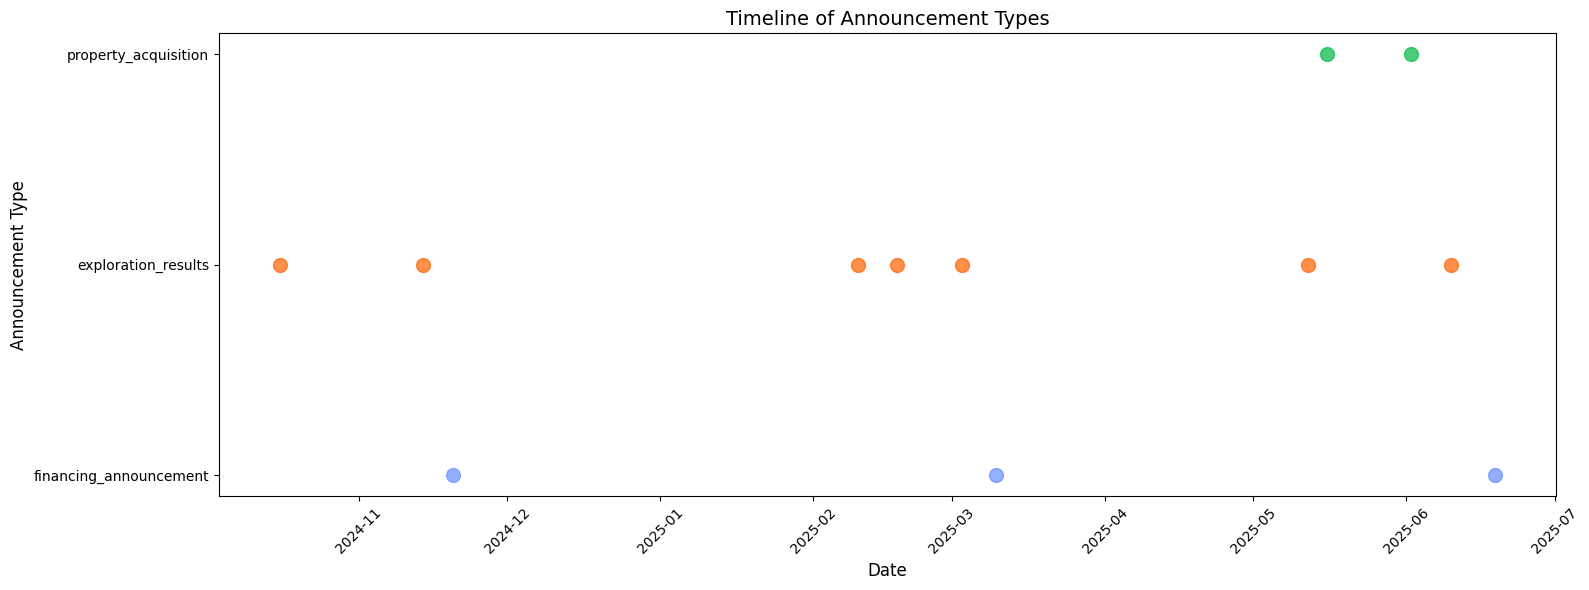

In [14]:
# Prepare announcements data
announcements_pd = announcements_cgc.toPandas()
announcements_pd['date-time'] = pd.to_datetime(announcements_pd['date-time'])

# Create timeline plot
fig, ax = plt.subplots(figsize=(16, 6))

# Get unique announcement types and assign colors
announcement_types = announcements_pd['type'].unique()
colors = plt.cm.Set3(np.linspace(0, 1, len(announcement_types)))
colors = [
    '#648FFF',
    '#FE6100',
    '#00B945'
]
color_map = dict(zip(announcement_types, colors))

# Plot each announcement type
for ann_type in announcement_types:
    subset = announcements_pd[announcements_pd['type'] == ann_type]
    ax.scatter(subset['date-time'], [ann_type]*len(subset), 
               c=[color_map[ann_type]], s=100, alpha=0.7, label=ann_type)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Announcement Type', fontsize=12)
ax.set_title('Timeline of Announcement Types', fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

It appears that financing announcements follow exploration_results announcements. This makes sense, as positive exploration results can lead to capital needs for further development. On the other hand, negative exploration results may also lead to financing to start a new exploration program. For you to find out if a more detailed feature can be extracted from the exploration results that would lead to refinancing!

# 2. Text Analysis

## 2.1 Data cleaning

*similar to Notebook 3*

In [15]:
# define data dir
data_dir = "./Data/"

In [16]:
# get all the names of the json files
json_names = [obs for obs in os.listdir(data_dir) if ".json" in obs]

# get all the paths of the json files
json_paths = [os.path.join(data_dir, obs) for obs in json_names]

In [17]:
# load the json files
json_dfs = [spark.read.option("multiLine", "true").json(obs) for obs in json_paths]

# Convert date string to proper date type
json_dfs = [df.withColumn("date", F.to_date("date", "MMMM d, yyyy")) for df in json_dfs]

# We only have data for one company
articles_df = json_dfs[0]
articles_df.printSchema()

root
 |-- content: string (nullable = true)
 |-- date: date (nullable = true)
 |-- title: string (nullable = true)
 |-- url: string (nullable = true)



In [18]:
# define puncutation and stopwords
PUNCTUATION = [char for char in punctuation if char not in ["!", "@", "#", '"']]
STOPWORDS = stopwords.words("english")

In [19]:
# define function to remove punctuation
def remove_punct(text):
    # remove punctuation
    text = "".join([char for char in text if char not in PUNCTUATION])
    return(text)

# register functions as udf
remove_punct_udf = F.udf(remove_punct, StringType())

In [20]:
def remove_stopwords(tokens):
    # remove stopwords
    tokens = [word for word in tokens if word.lower() not in STOPWORDS]
    return(tokens)

# register functions as udf
remove_stopwords_udf = F.udf(remove_stopwords, ArrayType(StringType()))

In [21]:
# Remove everything after "For Further Information, Please Contact:" including the string itself
articles_df = articles_df.withColumn("content",
                          F.regexp_replace(F.col("content"), 
                                          "For Further Information, Please Contact:.*", 
                                          ""))
articles_df.collect()[0]

Row(content='McEwen Inc. and Canadian Gold Corp. Announce Arrangement Agreement\nToronto, Ontario and Flin Flon, Manitoba – October 14, 2025 – McEwen Inc. (“McEwen“) (NYSE: MUX) (TSX:MUX) and Canadian Gold Corp. (“Canadian Gold“) (TSX-V:CGC) are pleased to announce that they have entered into a definitive agreement (the “Arrangement Agreement“) dated October 10, 2025, pursuant to which McEwen will acquire all of the issued and outstanding common shares of Canadian Gold by way of a statutory plan of arrangement (the “Proposed Transaction“). If the Proposed Transaction is approved by Canadian Gold shareholders and the Supreme Court of British Columbia, Canadian Gold will become a wholly-owned subsidiary of McEwen. Notice of a special meeting of Canadian Gold shareholders with a record date of October 30, 2025 and meeting date of December 5, 2025 has been filed on SEDAR+. The Proposed Transaction is expected to close in early January 2026.\nUnder the terms of the Arrangement Agreement, wh

In [22]:
# clean each article
cleaned_articles_df = articles_df \
    .withColumn("content", F.lower("content")) \
    .withColumn("title", F.lower("title")) \
    .withColumn("content", remove_punct_udf("content")) \
    .withColumn("title", remove_punct_udf("title")) \
    .withColumn("content", F.regexp_replace("content", "\n", " ")) \
    .withColumn("title", F.regexp_replace("title", "\n", " ")) \
    .withColumn("title_tokenized", F.split("title", " ")) \
    .withColumn("content_tokenized", F.split("content", " ")) \
    .withColumn("content_tokenized", remove_stopwords_udf("content_tokenized")) \
    .withColumn("title_tokenized", remove_stopwords_udf("title_tokenized")) \
    .withColumn("num_words_title", F.size("title_tokenized")) \
    .withColumn("num_words_content", F.size("content_tokenized")) \
    .cache()

## 2.2 Sentiment analysis

In [23]:
# define function to get polarity score of text document
def get_polarity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[0]

In [24]:
# define function to get subjectivity score of text document
def get_subjectivity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[1]

In [25]:
# register functions as udf
get_polarity_udf = F.udf(get_polarity, DoubleType())
get_subjectivity_udf = F.udf(get_subjectivity, DoubleType())

In [26]:
# text sentiment operations 
cleaned_articles_df = cleaned_articles_df.withColumn("polarity_title", get_polarity_udf(F.col("title"))) \
                                 .withColumn("polarity_content", get_polarity_udf(F.col("content"))) \
                                 .withColumn("subjectivity_title", get_subjectivity_udf(F.col("title"))) \
                                 .withColumn("subjectivity_content", get_subjectivity_udf(F.col("content"))) \
                                 .filter("num_words_title > 0 OR num_words_content > 0") \
                                 .drop("url") \
                                 .cache()

In [27]:
# load biweekly data
biweekly_data = spark.read.parquet("./Data/Biweekly Data/biweekly_data.parquet")
biweekly_data.printSchema()

root
 |-- biweekly_period: string (nullable = true)
 |-- period_start: date (nullable = true)
 |-- period_end: date (nullable = true)
 |-- period_open: double (nullable = true)
 |-- period_close: double (nullable = true)
 |-- period_high: double (nullable = true)
 |-- period_low: double (nullable = true)
 |-- avg_close: double (nullable = true)
 |-- period_return: double (nullable = true)
 |-- price_volatility: double (nullable = true)
 |-- return_volatility: double (nullable = true)
 |-- avg_intraday_range: double (nullable = true)
 |-- max_intraday_range: double (nullable = true)
 |-- total_volume: double (nullable = true)
 |-- avg_daily_volume: double (nullable = true)
 |-- max_daily_volume: double (nullable = true)
 |-- volume_volatility: double (nullable = true)
 |-- volume_concentration: double (nullable = true)
 |-- avg_volume_up_days: double (nullable = true)
 |-- avg_volume_down_days: double (nullable = true)
 |-- gap_count: long (nullable = true)
 |-- avg_gap_size: double (nu

In [28]:
# Join articles with biweekly periods based on date ranges
# An article belongs to a period if its date falls between period_start and period_end
articles_with_period = cleaned_articles_df.join(
    biweekly_data.select("period_start", "period_end", "biweekly_period", "next_announcement"),
    (F.col("date") >= F.col("period_start")) & (F.col("date") <= F.col("period_end")),
    how="right"  # right join to omit articles that don't fit in any period
)
articles_with_period.show(5)

+--------------------+----------+--------------------+--------------------+--------------------+---------------+-----------------+-------------------+--------------------+-------------------+--------------------+------------+----------+---------------+-----------------+
|             content|      date|               title|     title_tokenized|   content_tokenized|num_words_title|num_words_content|     polarity_title|    polarity_content| subjectivity_title|subjectivity_content|period_start|period_end|biweekly_period|next_announcement|
+--------------------+----------+--------------------+--------------------+--------------------+---------------+-----------------+-------------------+--------------------+-------------------+--------------------+------------+----------+---------------+-----------------+
|initial results f...|2024-10-16|initial results f...|[initial, results...|[initial, results...|             21|              794|0.04545454545454545| 0.05114137405804072|0.48484848484848

In [29]:
# Aggregate features by biweekly period
cleaned_articles_df_aggregated = articles_with_period.groupBy("period_start", "period_end", "biweekly_period", "next_announcement") \
    .agg(
        F.count("title").alias("num_articles"),
        F.avg("num_words_title").alias("avg_num_words_title"),
        F.avg("num_words_content").alias("avg_num_words_content"),
        F.avg("polarity_title").alias("avg_polarity_title"),
        F.avg("polarity_content").alias("avg_polarity_content"),
        F.avg("subjectivity_title").alias("avg_subjectivity_title"),
        F.avg("subjectivity_content").alias("avg_subjectivity_content"),
        # because averaging Vector types in Spark isn't possible. You can however do this using custom functions
    ) \
    .orderBy("period_start")

# To pandas for plotting
cleaned_articles_df_aggregated = cleaned_articles_df_aggregated.toPandas()

### 2.2.1 Distribution of number of articles

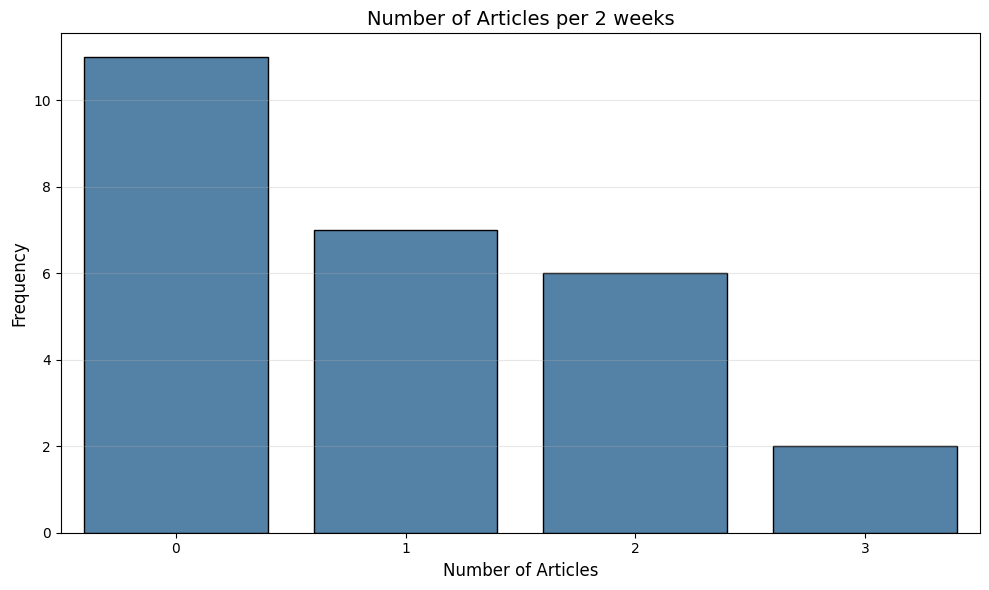

In [30]:
# inspect articles distribution
article_counts = cleaned_articles_df_aggregated["num_articles"]

plt.figure(figsize=(10, 6))
sns.countplot(x=article_counts, color='steelblue', edgecolor='black')
plt.xlabel('Number of Articles', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Number of Articles per 2 weeks', fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2.2 Sentiment and article count over time plot
To make the plot more comprehensible, the data is aggregated per week.

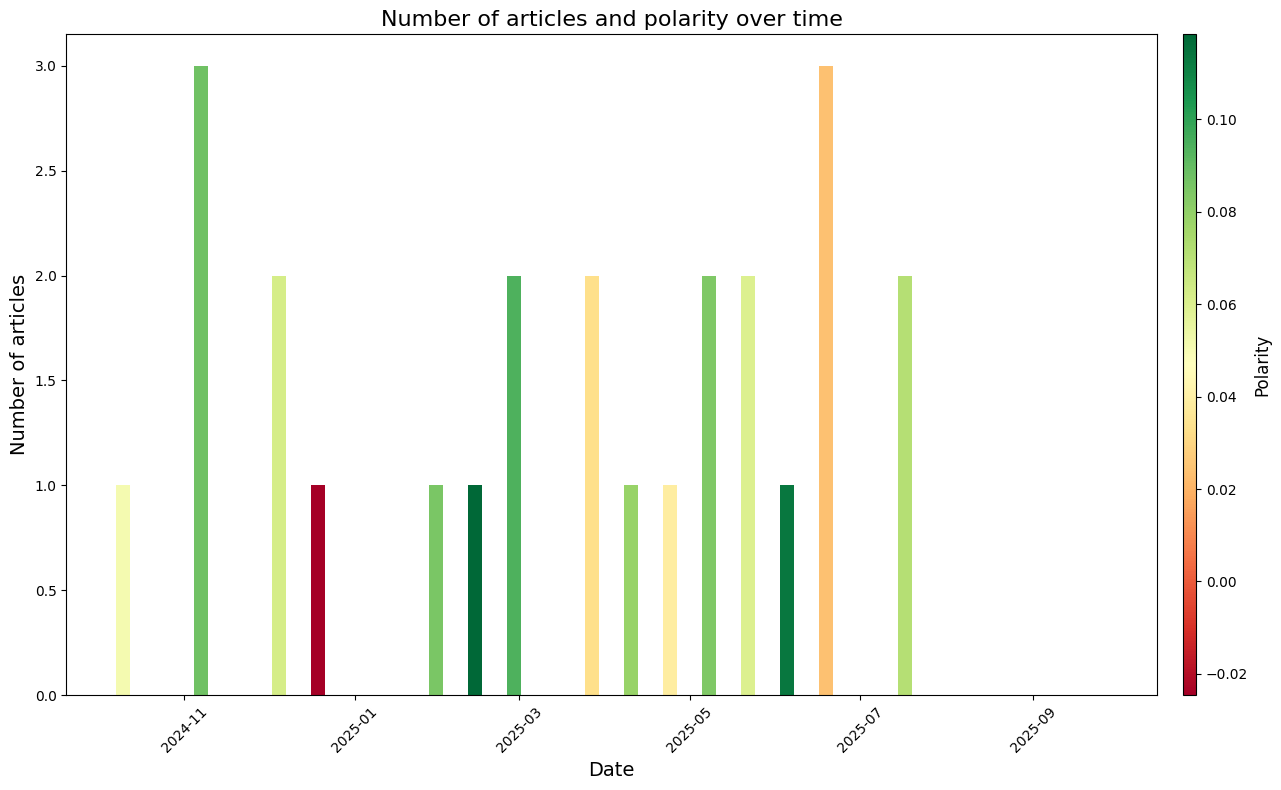

In [31]:
# normalize polarity values for the color mapping
norm = plt.Normalize(min(cleaned_articles_df_aggregated['avg_polarity_content']), max(cleaned_articles_df_aggregated['avg_polarity_content']))
cmap = sns.color_palette("RdYlGn", as_cmap=True)
# map colors based on the polarity value for each bar
colors = [cmap(norm(polarity)) for polarity in cleaned_articles_df_aggregated['avg_polarity_content']]

# bar plot
plt.figure(figsize=(14, 8))
bars = plt.bar(
    x=cleaned_articles_df_aggregated['period_start'], 
    height=cleaned_articles_df_aggregated['num_articles'], 
    color=colors,
    alpha=1,
    width=5
)

# add a color bar to indicate polarity
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, aspect=50, pad=0.02, ax=plt.gca())
cbar.set_label('Polarity', fontsize=12)

# format plot
plt.title("Number of articles and polarity over time", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Number of articles", fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [32]:
### 2.2.3 Most frequent words in articles
from collections import Counter
# collect all content tokens
all_content_tokens = cleaned_articles_df.select(F.explode("content_tokenized").alias("token")).rdd.flatMap(lambda x: x).collect()
# count word frequencies
word_counts = Counter(all_content_tokens)
# filter out stopwords and short words
filtered_word_counts = {word: count for word, count in word_counts.items() if word not in (STOPWORDS+["canadian", "gold", "corp", "inc"]) and len(word) > 2}

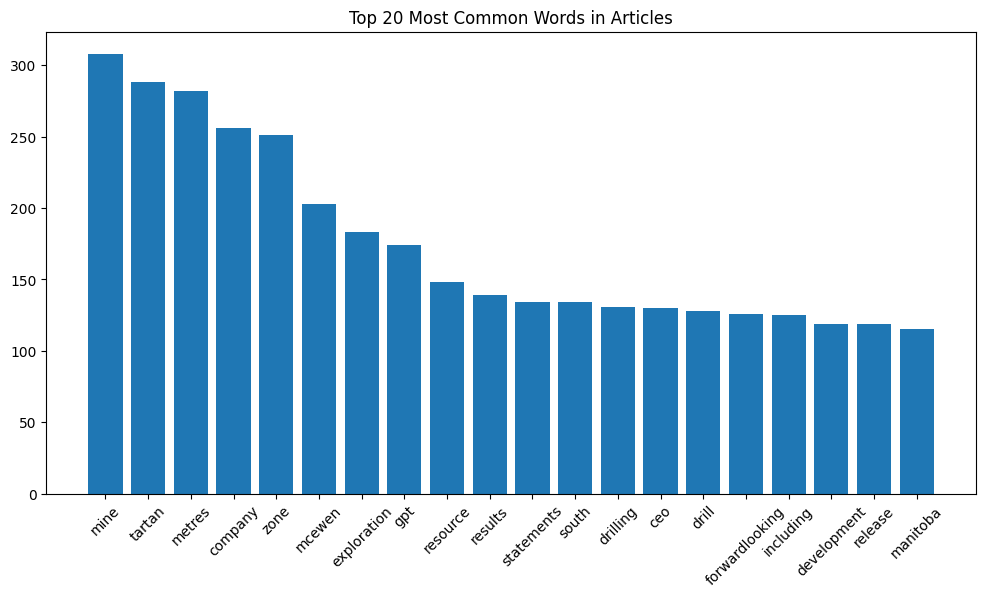

In [33]:
# get the 20 most common words
most_common_words = Counter(filtered_word_counts).most_common(20)
# plot the distribution
import matplotlib.pyplot as plt

words, counts = zip(*most_common_words)
plt.figure(figsize=(12, 6))
plt.bar(words, counts)
plt.xticks(rotation=45)
plt.title("Top 20 Most Common Words in Articles")
plt.show()

## 2.3 Word cloud
Let's look at the exploration results articles in more detail. A word cloud is a visual representation of text data, where the size of each word indicates its frequency or importance within the text. Word clouds are often used to quickly convey the most prominent themes or topics in a body of text.

In [34]:
# import wordcloud
from wordcloud import WordCloud

In [35]:
# join text data with announcement types
announcements = pd.read_csv("./Data/Canadian_gold_corp_announcements.csv")
cleaned_articles_pd = cleaned_articles_df.toPandas()
cleaned_articles_pd.date = pd.to_datetime(cleaned_articles_pd.date)
announcements['date-time'] = pd.to_datetime(announcements['date-time'])
joined_articles = cleaned_articles_pd.merge(announcements[['date-time', 'type']], left_on='date', right_on='date-time', how='left')

In [36]:
# get all cleaned text 
exploration_results_all_text = " ".join(joined_articles[joined_articles["type"] == "exploration_results"]["content"].tolist())

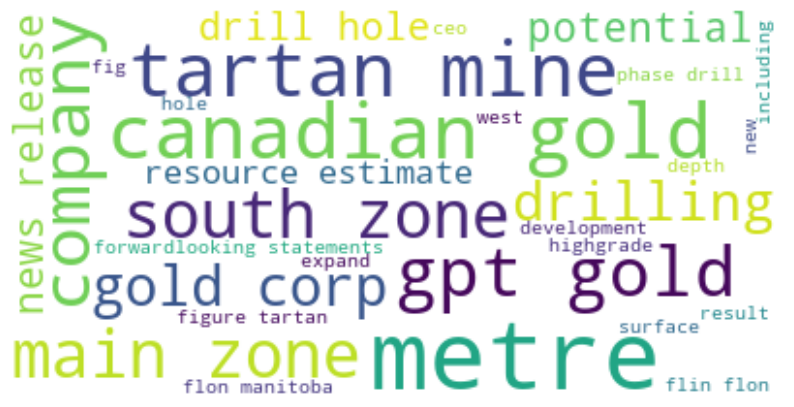

In [37]:
# print wordcloud
wordcloud = WordCloud(max_font_size=50, max_words=30, background_color="white").generate(exploration_results_all_text)
plt.figure(figsize=(10, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

This can use some pre-processing to get rid of obvious words like the company name, "gold", etc.

## 2.4 LDA Topic Modeling

In [38]:
# import lda
from pyspark.ml.feature import Tokenizer, CountVectorizer, IDF, StopWordsRemover
from pyspark.ml.clustering import LDA

In [39]:
# define stopwordsremover
SW = StopWordsRemover(inputCol="content_tokenized", outputCol="tokenized_text", stopWords= STOPWORDS+["canadian", "gold", "corp", "inc"]) # For the topic models we also want to remove obvious words

# define term frequencies
TF = CountVectorizer(inputCol="tokenized_text", outputCol="features", vocabSize=5000, minDF=10.0)

# define LDA
LDA_model = LDA(featuresCol="features", k=5, maxIter=100)

In [40]:
# define LDA pipeline
LDA_pipeline = Pipeline(stages=[SW, TF, LDA_model]).fit(cleaned_articles_df)

In [41]:
# get lda model
tfModel = LDA_pipeline.stages[-2]
ldaModel = LDA_pipeline.stages[-1]

In [42]:
# get lda topics
lda_topics = ldaModel.describeTopics(maxTermsPerTopic=10).toPandas()

In [43]:
# get vocabulary
vocabulary = tfModel.vocabulary

In [44]:
# get topic
def get_topic(indices):
    
    # get words
    for idx in indices:
        word = vocabulary[idx]
        print(word)

In [45]:
# show topics
for i in range(len(lda_topics)):
    topic = lda_topics["topic"].iloc[i]
    idx = lda_topics["termIndices"].iloc[i]
    print("\nTOPIC %s:" %i)
    get_topic(idx)



TOPIC 0:
press
samples
manitoba
tartan
depth
two
former
within
flin
properties

TOPIC 1:

metres
zone
main
including
100
estimate
western
mine
gpt

TOPIC 2:

metres
zone
mine
gpt
drill
tartan
2
drilling
including

TOPIC 3:
cgc
120
phase
results
qc
table
capital
common
mining
details

TOPIC 4:

mcewen
mine
tartan
company
exploration
statements
forwardlooking
hammond
reef


In [46]:
# function to link words from vocabulary to termIDs
def map_termID_to_Word(termIndices):
      words = []
      for termID in termIndices:
          words.append(vocabulary[termID])
      return words

# as udf
udf_map_termID_to_Word = F.udf(map_termID_to_Word , ArrayType(StringType()))

In [47]:
# retrieve topic descriptions
topics = ldaModel.describeTopics()
ldatopics_mapped = topics.withColumn("topic_desc", udf_map_termID_to_Word(topics.termIndices))
ldatopics_mapped_pd = ldatopics_mapped.toPandas()

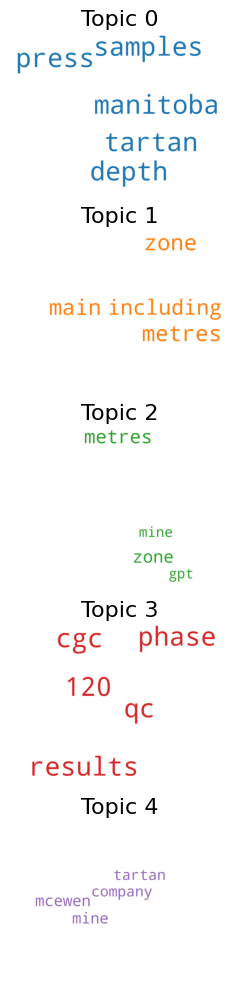

In [48]:
# plot wordcloud for top n words in each topic
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors

cols = [color for name, color in mcolors.TABLEAU_COLORS.items()]  # more colors: 'mcolors.XKCD_COLORS'

cloud = WordCloud(background_color='white',
                  width=2500,
                  height=1800,
                  max_words=5,
                  colormap='tab10',
                  color_func=lambda *args, **kwargs: cols[i],
                  prefer_horizontal=1.0)

fig, axes = plt.subplots(5, 1, figsize=(10,10), sharex=True, sharey=True)

for i, ax in enumerate(axes.flatten()):
    fig.add_subplot(ax)

    term_weights = ldatopics_mapped_pd.iloc[i,2]
    topic_words = ldatopics_mapped_pd.iloc[i,3]

    topic_dict = dict(map(lambda i,j : (i,j) , topic_words, term_weights))
    cloud.generate_from_frequencies(topic_dict, max_font_size=300)
    plt.gca().imshow(cloud)
    plt.gca().set_title('Topic ' + str(i), fontdict=dict(size=16))
    plt.gca().axis('off')


plt.subplots_adjust(wspace=0, hspace=0)
plt.axis('off')
plt.margins(x=0, y=0)
plt.tight_layout()
plt.show()

**Note:** Next to removing stopwords, stemming or lemmatization can help create more informative topics. These topics can also be used as features for predictive models.

# 3 Model evaluation & explanation

*Similar to notebook 2*

In [49]:
biweekly_data.show()

+---------------+------------+----------+-----------+------------+-----------+----------+-------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+--------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+--------------------+-------------------+-------------------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+--------------------+------------------+------------------+-----------------+
|biweekly_period|period_start|period_end|period_open|period_close|period_high|period_low|          avg_close|       period_return|    price_volatility|   return_volatility|  avg_intraday_range|  max_intraday_range|total_volume|  

## 3.1 Time-based split

*Similar to notebook 2*

In [50]:
# Use the first 2/3 of the data for training and the last 1/3 for testing
train_size = int(biweekly_data.count() * 0.67)
train_df = biweekly_data.limit(train_size)

# Use the remaining data for testing
test_df = biweekly_data.subtract(train_df)

## 3.2 Remove missing values

*Similar to notebook 2*

In [51]:
train_df = train_df.filter(F.col("prev_period_return").isNotNull())
train_df = train_df.fillna(0)

In [52]:
# We again fill the missing values for avg_volume features with 0
test_df = test_df.fillna(0)

## 3.3 Feature selection
Feature selection is a crucial step in preparing data for machine learning models when interpretability is a concern, helping to reduce complexity by focusing on the most relevant information. In this process, we use a correlation matrix to identify relationships between features. The correlation matrix provides a systematic way to detect highly correlated features, which may introduce redundancy and **multicollinearity** into the model. This can lead to unstable estimates of coefficients in linear models or variable importance scores in tree-based models, making it difficult to interpret the influence of individual features.

By examining these correlations, we can identify and remove features that are strongly correlated with one another, ensuring that the model only uses independent variables that each add unique value. This approach not only improves model interpretability but also reduces overfitting risk and training efficiency, especially when the dimensionality of the data is high and when using a linear model. Tree-based models are generally more robust to multicollinearity, but removing correlated features can still enhance interpretability.

When using a linear model, using Lasso or Elastic Net regularization is preferred, as these methods can inherently handle multicollinearity by penalizing the coefficients of correlated features, effectively selecting one feature from a group of correlated features while shrinking the others towards zero.

**NOTE**: See `band_width` and `macd_histogram` explanations above in feature engineering

In [53]:
# Feature selection
exclude_columns = ["biweekly_period", "period_start", "period_end", "next_announcement"]
feature_columns = [col for col in train_df.columns if col not in exclude_columns]
assembler = VectorAssembler(inputCols=feature_columns, outputCol="features")

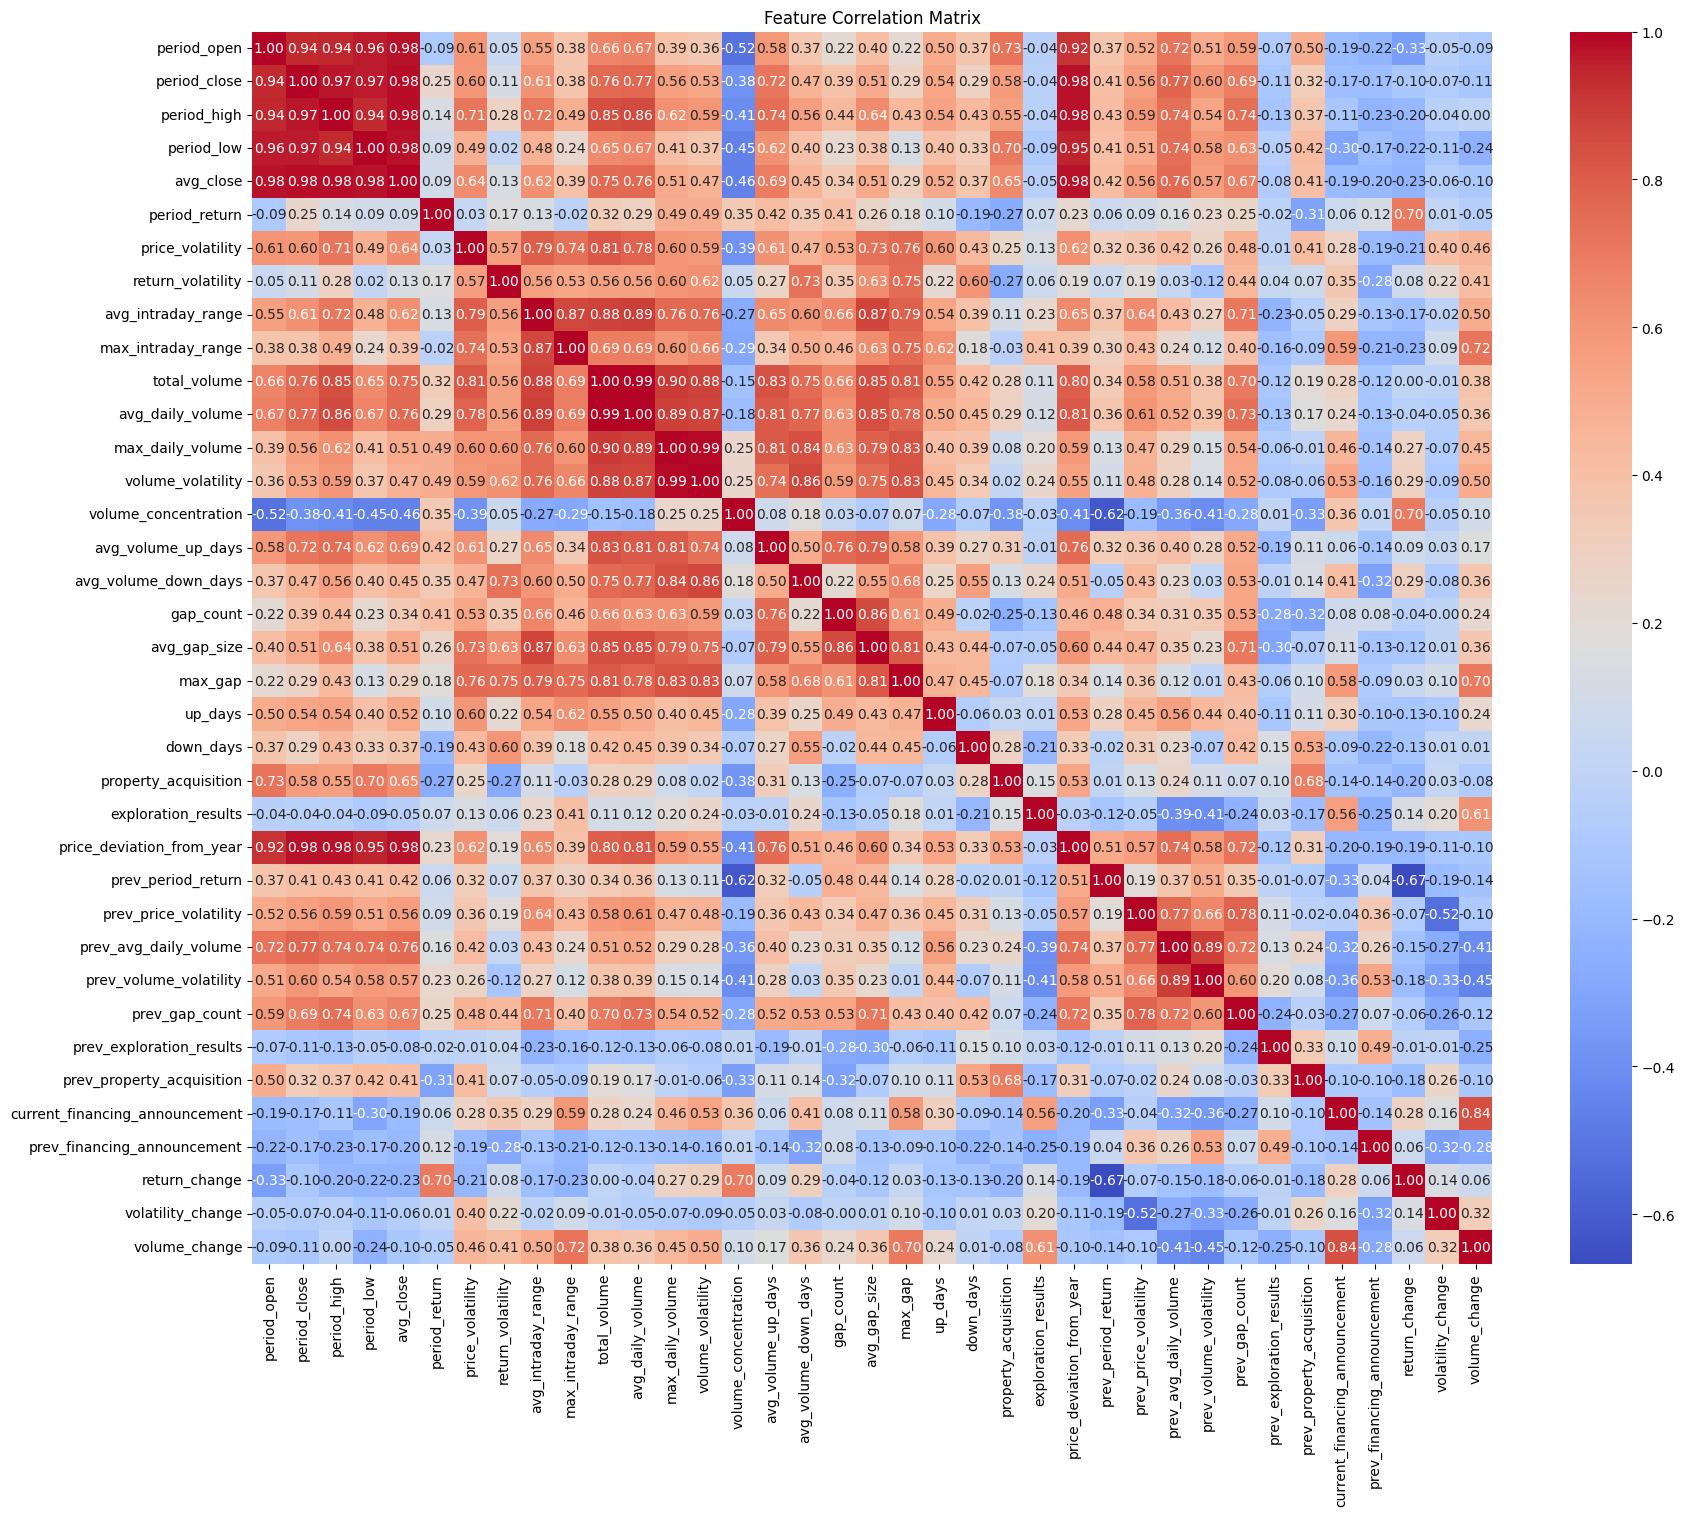

In [54]:
# assemble the features into a vector
df_vector = assembler.transform(train_df).select("features")

# calculate the correlation matrix
correlation_matrix = Correlation.corr(df_vector, "features").head()[0]

# convert the DenseMatrix to a NumPy array
corr_array = np.array(correlation_matrix.toArray())

# create a Pandas DataFrame from the correlation array for visualization
corr_df = pd.DataFrame(corr_array, columns=feature_columns, index=feature_columns)

# plot the heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

In [55]:
# Some features seem to be correlated. For interpretation purposes, we'll remove some correlated ones.
exclude_columns = ["avg_close", "biweekly_period", "period_start", "period_end", "next_announcement", "period_open", "period_close", "period_high", "period_low", "total_volume", "avg_intraday_range", "volume_volatility"]
feature_columns = [col for col in train_df.columns if col not in exclude_columns]
VA = VectorAssembler(inputCols=feature_columns, outputCol="features")

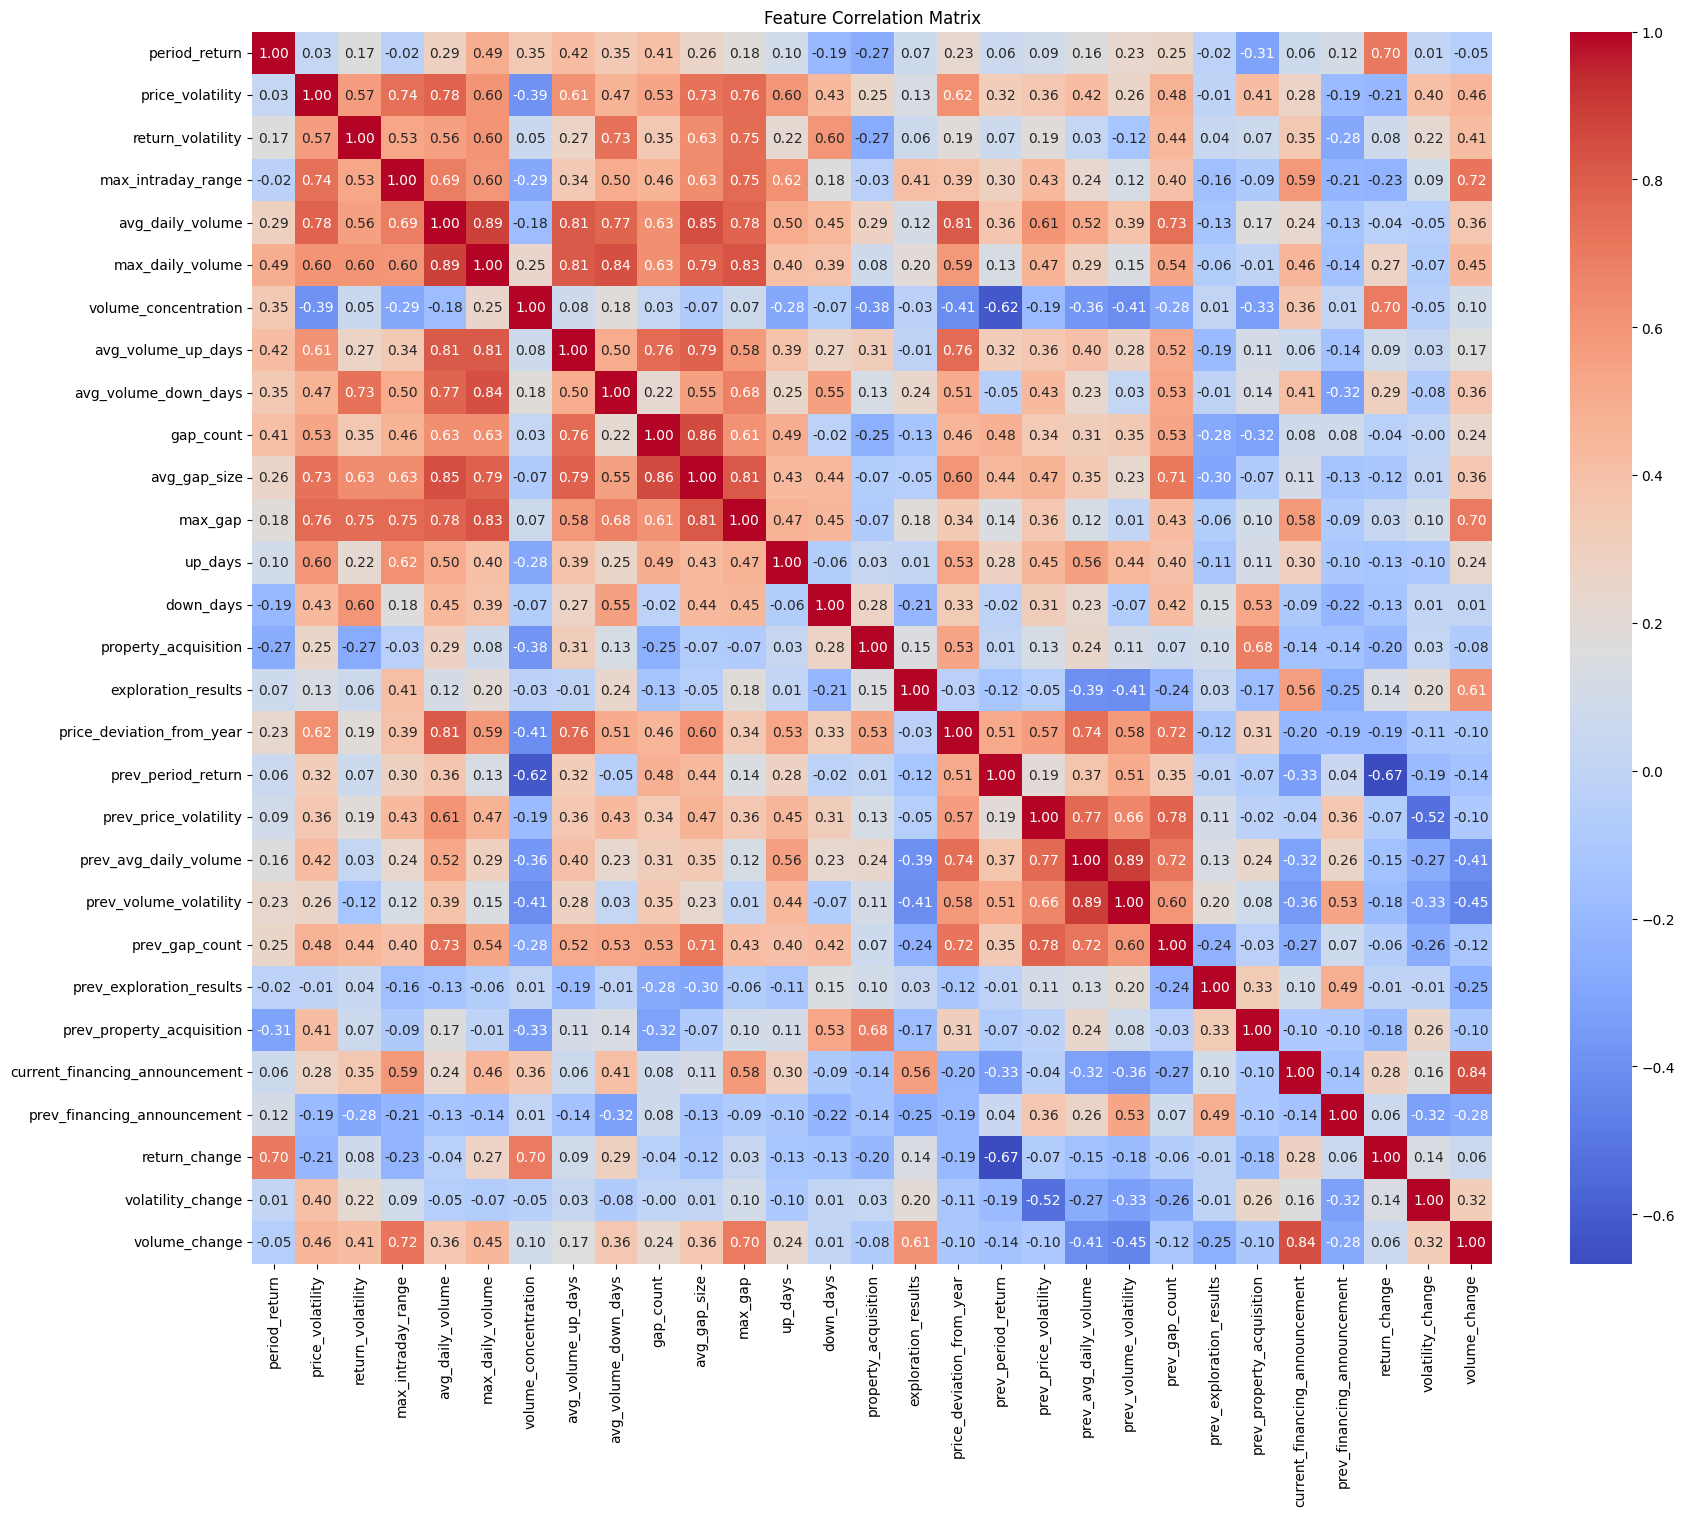

In [56]:
# assemble the features into a vector
df_vector = VA.transform(train_df).select("features")

# calculate the correlation matrix
correlation_matrix = Correlation.corr(df_vector, "features").head()[0]

# convert the DenseMatrix to a NumPy array
corr_array = np.array(correlation_matrix.toArray())

# create a Pandas DataFrame from the correlation array for visualization
corr_df = pd.DataFrame(corr_array, columns=feature_columns, index=feature_columns)

# plot the heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

## 3.4 Gradient-Boosted Tree Classifier

In [57]:
# define boosting model
GBT = GBTClassifier(featuresCol="features", labelCol="next_announcement")

# fit model on train
gbt_pipeline = Pipeline(stages=[VA, GBT])

# model training
gbt_model = gbt_pipeline.fit(train_df)

In [58]:
# predictions
gbt_predictions = gbt_model.transform(test_df)

In [59]:
# show predictions
gbt_predictions.select("period_start", "period_end", "next_announcement", "prediction").show()

+------------+----------+-----------------+----------+
|period_start|period_end|next_announcement|prediction|
+------------+----------+-----------------+----------+
|  2025-08-14|2025-08-27|                0|       0.0|
|  2025-06-19|2025-07-02|                0|       0.0|
|  2025-07-31|2025-08-13|                0|       0.0|
|  2025-06-05|2025-06-18|                1|       0.0|
|  2025-09-25|2025-10-08|                0|       0.0|
|  2025-08-28|2025-09-10|                0|       0.0|
|  2025-09-11|2025-09-24|                0|       0.0|
|  2025-07-03|2025-07-16|                0|       0.0|
|  2025-07-17|2025-07-30|                0|       0.0|
+------------+----------+-----------------+----------+



*Similar to notebook 2*

## 3.5 Evaluation

In [60]:
def calculate_classification_metrics(predictions, label_col, prediction_col):
    # calculate true positives, true negatives, false positives, false negatives
    tp = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 1)).count()
    tn = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 0)).count()
    fp = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 1)).count()
    fn = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 0)).count()

    # calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # calculate precision
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0  
    
    # calculate recall
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0.0  
    
    # calculate F1 measure
    f1_measure = 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0.0  

    # print the metrics
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 measure: {f1_measure}")
    
    return accuracy, precision, recall, f1_measure

In [61]:
# get metrics
gbt_accuracy, gbt_precision, gbt_recall, gbt_f1_measure = calculate_classification_metrics(gbt_predictions, 'next_announcement', 'prediction')

Accuracy: 0.8888888888888888
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [62]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")
gbt_AUC = evaluator.evaluate(gbt_predictions)
print(f"AUC: {gbt_AUC:.4f}")

AUC: 0.5000


### 3.5.1 Confusion matrix

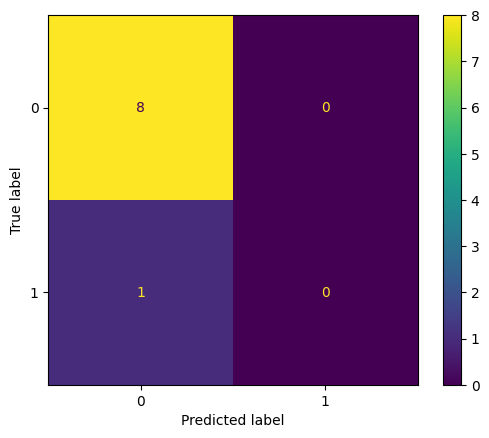

In [63]:
# import confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# get predictions and labels
preds_and_labels = gbt_predictions.select(['prediction','next_announcement']) \
                                  .withColumn('label', F.col('next_announcement').cast(FloatType())) \
                                  .orderBy('prediction') \
                                  .toPandas()

# get confusion matrix
cm = confusion_matrix(preds_and_labels["label"], preds_and_labels["prediction"], labels=[0, 1])

# get confusion matrix figure
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

# plot figure
disp.plot()
plt.show()

**Note:** The confusion matrix confirms the low precision and recall. You could experiment with using techniques to deal with this class imbalance such as sampling, adjusting the decision threshold or using different evaluation metrics.

### 3.5.2 ROC-Curve

In [64]:
# import required packages
from sklearn.metrics import roc_curve

# get array of labels
l = np.squeeze(np.array(gbt_predictions.select("next_announcement").collect()))

# get array of predicted probabilities
p = np.squeeze(np.array(gbt_predictions.select("probability").collect()))[:, 1]

# get fpr and tpr
fpr, tpr, t = roc_curve(l, p)

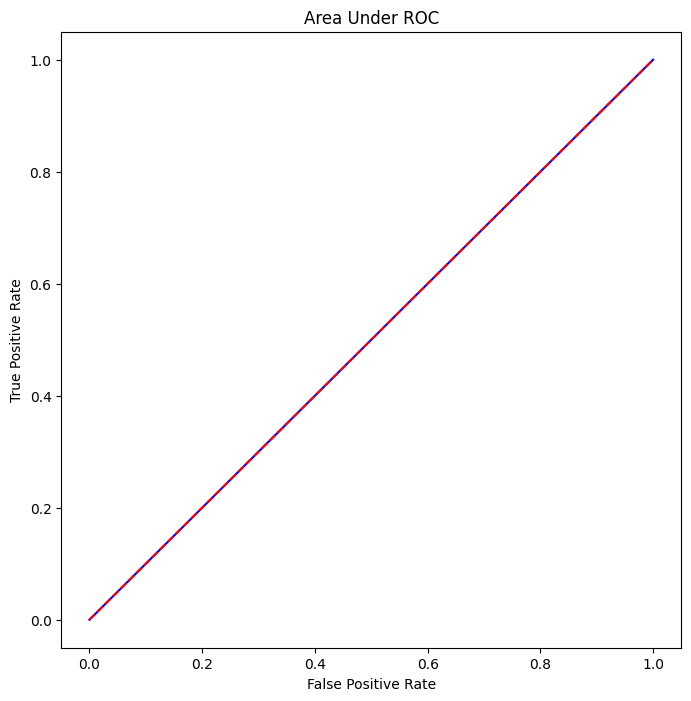

In [65]:
# plot ROC curve
plt.figure(figsize=(8, 8))
plt.plot(fpr, tpr, color="blue")
# dashed line for random classifier
plt.plot([0, 1], [0, 1], "--", color="red")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Area Under ROC")
plt.show()

### 3.5.3 Lift curve

In [66]:
# get labels and predictions
l_p = pd.DataFrame({"label": l, "prediction": p})

# sort by probability
l_p = l_p.sort_values(by="prediction", ascending=False)

# check
l_p.head(5)

,label,prediction
0,0,0.043647
1,0,0.043647
2,0,0.043647
3,1,0.043647
4,0,0.043647


In [67]:
# get average response rate
avg_response_rate = np.mean(l_p["label"])

# define empty container for lift scores
lift_scores = []

# get chunk size 
chunk_size = int(len(l_p) / 10)

# loop through 10 chunks (NOTE: we only have 48 obs in test set!)
for i in range(10):
  # get chunk of data
  chunk = l_p.iloc[i*chunk_size:(i+1)*chunk_size]
  # get model response rate
  model_response_rate = np.mean(chunk["label"])
  # get lift
  lift_score = model_response_rate / avg_response_rate
  # add to container
  lift_scores.append(lift_score)

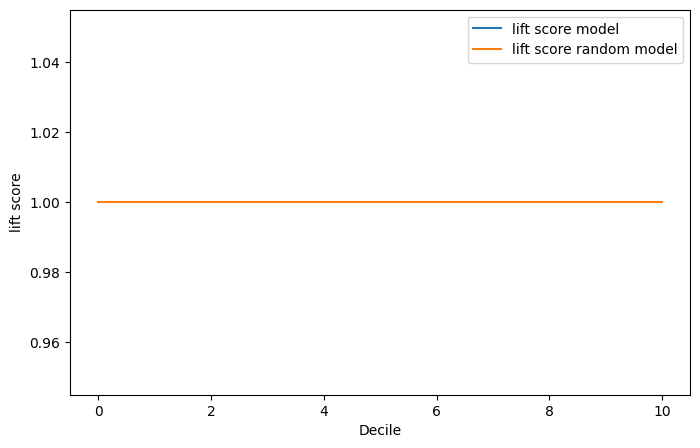

In [68]:
# plot lift scores
plt.figure(figsize=(8, 5))
plt.plot(range(10), lift_scores, label="lift score model")
plt.plot([0, 10], [1, 1], "-", label="lift score random model")
plt.xlabel("Decile")
plt.ylabel("lift score")
plt.legend(loc="upper right")
plt.show()

The AUC and lift score both are 0, so the roc curve is a straight diagonal line and the lift curve is a horizontal line at 1. This means that the model is not better than random guessing.

## 3.6 Model explanation

### 3.6.1 Feature importance
Measures the marginal contribution of each feature to a model's decisions 

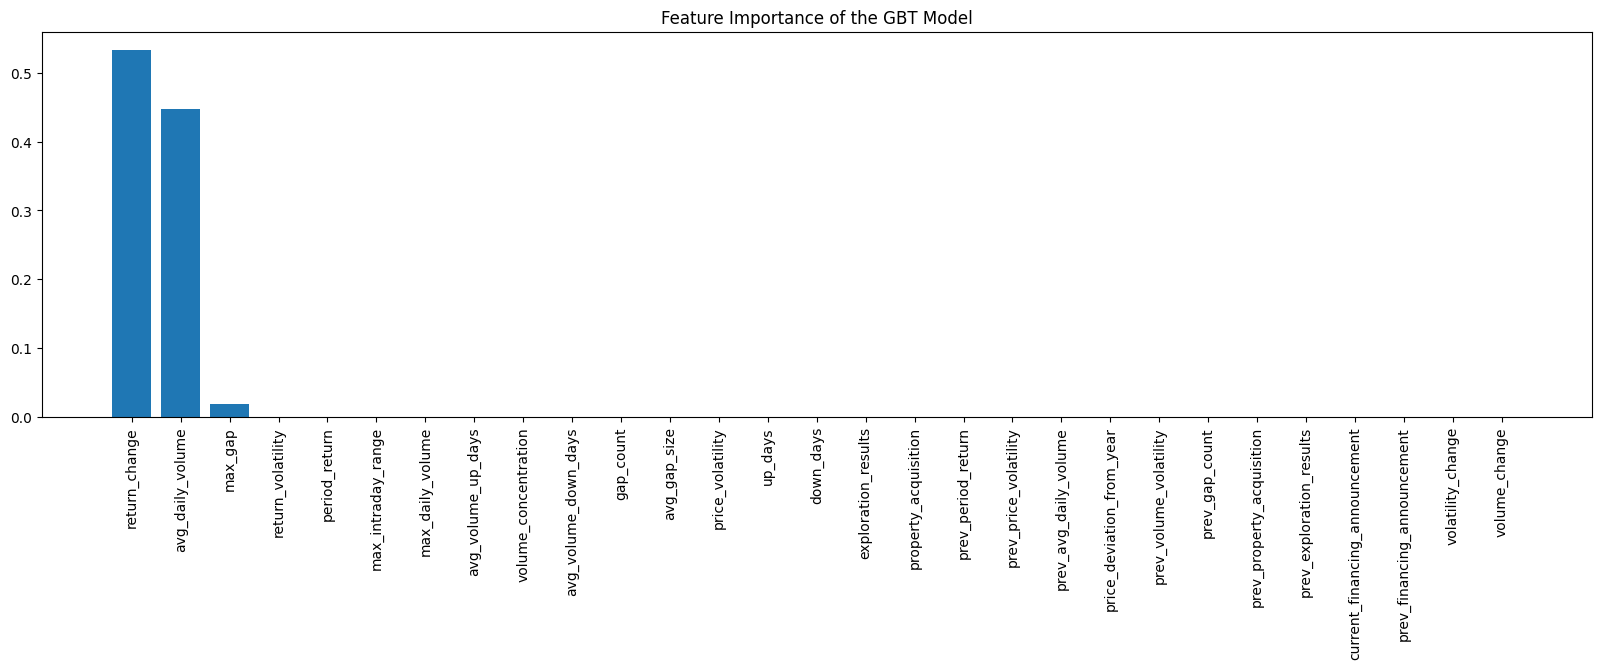

In [69]:
# inspect feature importance
feature_importance = gbt_model.stages[-1].featureImportances.toArray() # default: mean decrease in gini

# define all the features
all_feature_names = feature_columns

df_importances = pd.DataFrame(
   dict(
      names = all_feature_names,
      importances = feature_importance
   )
)

# plot
plt.figure(figsize=(20, 5))
plt.bar('names', 'importances', data = df_importances.sort_values('importances', ascending=False))
plt.title("Feature Importance of the GBT Model")
plt.xticks(rotation=90)
plt.show()

### 3.6.2 Shapley values
SHAP (SHapley Additive exPlanations) is a model-agnostic post-hoc explanation method based on game theory for global and local explanations. It measures how much each feature contributes to the model's prediction, as well as the direction of its influence. The package contains multiple insightful plots that contain a lot of information, though interpreting them requires careful attention and may be difficult for those unfamiliar with these visualizations. Below, we demonstrate two examples:

In [70]:
import shap
shap.plots.initjs()

c:\Users\simondla\GitHub\Assignment-2526\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning:

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [71]:
# cast test data to pandas
test_df_pd = test_df.select(feature_columns).toPandas()

In [72]:
# the TreeExplainer makes use of the tree structure, ignoring decision paths that include the absent features instead of random sampling feature values. It is also more efficient.
explainer = shap.TreeExplainer(gbt_model.stages[-1])
shap_values = explainer(test_df_pd, check_additivity = False)
shap_pandas_df = pd.DataFrame(shap_values.values, columns = test_df_pd.columns)

#### Violin summary plot
There are different types of summary plots included in the SHAP package. They all give a global explanation of the model. The violin plot gives us insights of what effect each feature has on the outcome, dependent on the feature value (blue = low, red = high). Outliers are shown as points outside the kernel densities. You can see that it is difficult to make global conclusions about the model based on this plot.

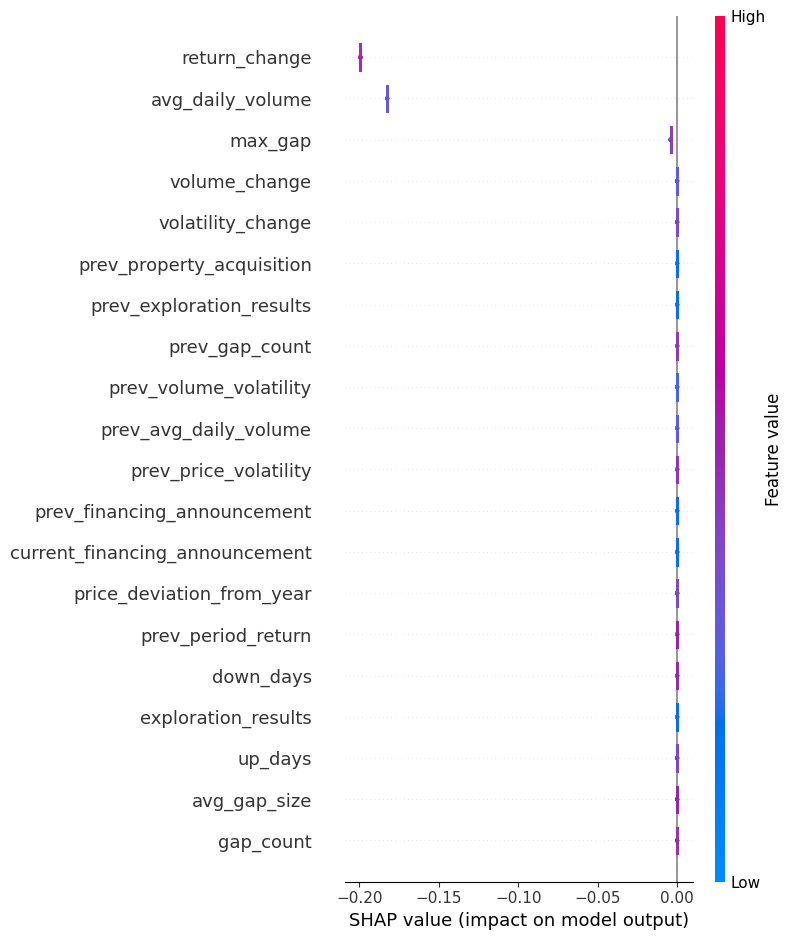

In [73]:
shap.summary_plot(shap_values, test_df_pd, feature_names=feature_columns, plot_type="violin")

**Note**: In this case, the shap values are calculated on the holdout set. Calculating them on the training set can slightly alter the retrieved explanations, especially when there is overfitting or distribution shift. Because the global explanations are made of aggregated instance-level explanations, caution is needed when extrapolating global training set explanations to the test set, especially when test set performance is lower.

#### Dependence plot
Using shap values, it is possible to create dependence plots. It visualizes the relationship between the model score and one predictor. On the plot below, an additional feature was added to color the observations. This lets us detect interactions between the two variables, as is the case for the variables on the plot below.

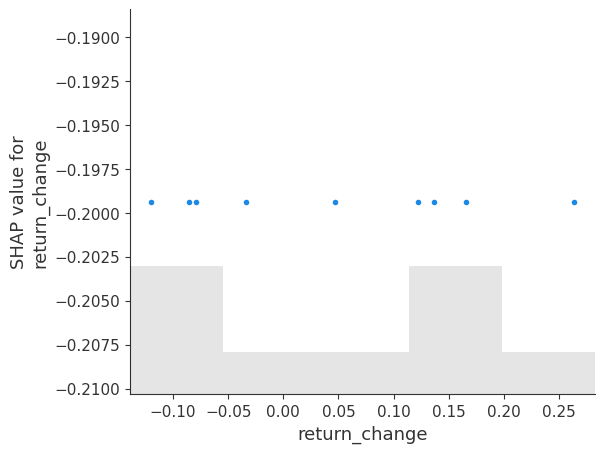

In [74]:
shap.plots.scatter(shap_values[:, 'return_change'])

#### Waterfall plot
For local explanations, waterfall plots can be used. The bottom of the plot starts as the expected value of the model output (for the classification case in log-odds, so a negative value implies a predicted probability of less than 0.5). Each row shows how the contribution of a feature moves the prediction from the expected value, given the feature values given on the left in grey. Because this is a local explanation, **no global conclusions** can be made. For example, it isn't guaranteed that a decrease in return_change will lead to a lower predicted probability in general based on this plot. This would only be the case if the model was additive, such as is the case for logistic regression. Contrarily, the relationships modeled by tree-based ensembles are more complex, including thresholds and interactions.

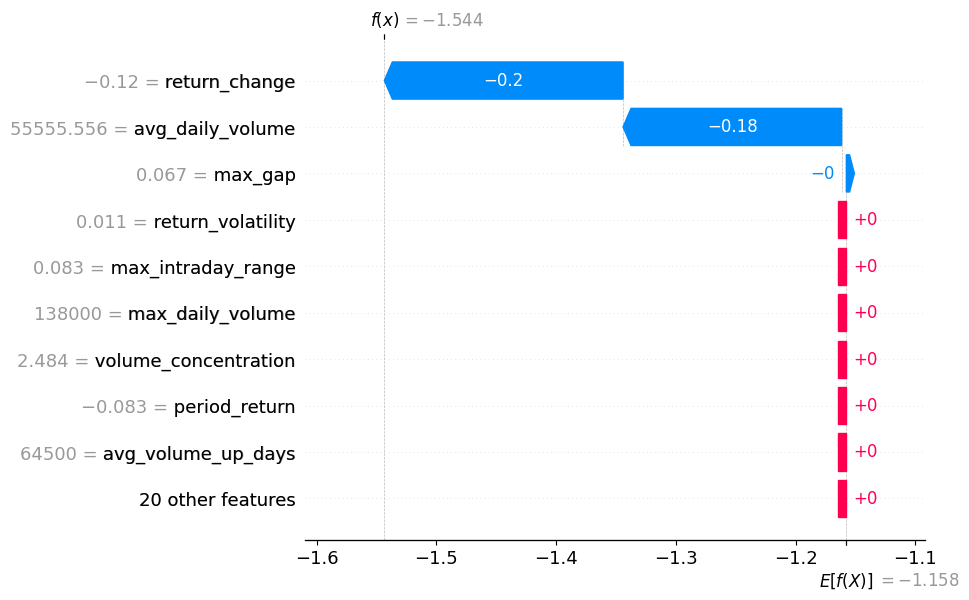

In [75]:
shap.plots.waterfall(shap_values=shap_values[1])

**Note:** Many different types of plots exist in the SHAP package and there. Experiment to see which ones give the clearest insights. Of course when we only have this very limited test set and model performance is low, the explanations may not be insightful.